# 基差策略

先读数据，再把基差变成分数，最后按分数买卖。运行前安装 numpy、pandas、matplotlib 和 jupyterlab。

这里放了 16 个商品、2024 年下半年的样例。这段是看过结果后挑出的教学区间，只演示计算流程，不代表完整历史表现。


## 推荐阅读

可以先跑代码，想补背景时再回来读。两篇都不用一口气读完。

1. [Facts and Fantasies about Commodity Futures](https://www.nber.org/papers/w10595) — Gary Gorton、K. Geert Rouwenhorst，2004 年工作论文，2006 年修订。先看摘要和收益图，了解商品期货这类资产。论文中的充分抵押组合与这里的多空策略口径不同。
2. [Commodity Futures Prices: Some Evidence on Forecast Power, Premiums, and the Theory of Storage](https://doi.org/10.1086/296385) — Eugene F. Fama、Kenneth R. French，1987。接着追问现货与期货的价差，先看基差定义和文章提出的问题，推导可以留到以后。全文可能需要机构权限。


## 读入行情

每行是一个合约在某个交易日的记录。`close` 是收盘价，`open_interest` 是持仓量；`symbol` 区分商品，`contract` 区分月份合约。


In [1]:
# 首次使用，请先在终端安装：python -m pip install numpy pandas matplotlib jupyterlab
# 在本章目录启动 Jupyter，打开这份 notebook，从上到下运行。
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('data')
market = pd.read_csv(DATA / 'market.csv', parse_dates=['date'])
assert not market.duplicated(['date', 'contract']).any()
assert market['close'].gt(0).all()
dates = pd.DatetimeIndex(sorted(market['date'].unique()))
prices = market.pivot(index='date', columns='contract', values='close').reindex(dates)
interest = market.pivot(index='date', columns='contract', values='open_interest').reindex(dates)

# 昨天持仓量最大的合约，作为今天的代表合约。
lag_interest = interest.shift(1).stack().rename('lag_interest').reset_index()
lag_interest.columns = ['date', 'contract', 'lag_interest']
selected = market.merge(lag_interest, on=['date', 'contract'], how='inner')
selected = selected.sort_values(['date', 'symbol', 'lag_interest', 'contract'])
selected = selected.drop_duplicates(['date', 'symbol'], keep='last')
grid = pd.MultiIndex.from_product([dates, sorted(market.symbol.unique())], names=['date', 'symbol'])
panel = selected.set_index(['date', 'symbol']).reindex(grid).reset_index()
panel = panel.sort_values(['symbol', 'date'])
print(f'样例：{dates.min():%Y-%m-%d} 至 {dates.max():%Y-%m-%d}')
market.head()


样例：2024-07-01 至 2024-12-31


,date,symbol,contract,close,open_interest
0,2024-07-01,AG,AG2407,7717.0,7474.0
1,2024-07-01,AG,AG2408,7728.0,305631.0
2,2024-07-01,AG,AG2409,7737.0,21707.0
3,2024-07-01,AG,AG2410,7748.0,184679.0
4,2024-07-01,AG,AG2411,7762.0,6093.0


In [2]:
def history_rank(series):
    # 看今天的基差率排在历史上的什么位置。少于 60 个有效值时先不算。
    return series.rolling(756, min_periods=60).apply(
        lambda x: 100 * (x.dropna() <= x.iloc[-1]).mean() if pd.notna(x.iloc[-1]) else np.nan)

def change_score(series, scale):
    # 把变化量压到 0～100 分。变化为 0 时是 50 分。
    return 50 * (1 + np.tanh(series / scale))

def blend(parts, weights):
    # 缺哪个分量，就暂时不用它；剩下的权重重新加到 1。
    table = pd.concat(parts, axis=1)
    weights = np.asarray(weights)
    total = table.notna().mul(weights).sum(axis=1).replace(0, np.nan)
    return table.mul(weights).sum(axis=1) / total


## 算基差分数

正基差表示现货比期货贵。这里只用基差率打分：60% 看自身历史位置，25% 看近 5 日变化，15% 看近 20 日变化。


In [3]:
basis = pd.read_csv(DATA / 'basis.csv', parse_dates=['date'])
assert not basis.duplicated(['date', 'contract']).any()
panel = panel.merge(basis, on=['date', 'contract'], how='left', validate='many_to_one')
panel = panel.sort_values(['symbol', 'date'])
group = panel.groupby('symbol', sort=False)['basis_rate']

# 基差率单位是百分点：5 表示 5%。正数表示现货比期货贵。
# 60% 看历史位置，25% 看近 5 日变化，15% 看近 20 日变化。
level = group.transform(history_rank)
short_change = change_score(group.diff(5), 2)
long_change = change_score(group.diff(20), 4)
panel['basis_score'] = blend([level, short_change, long_change], [.60, .25, .15])
# 分数向后挪一天，今天的分数明天用。
panel['basis_signal'] = panel.groupby('symbol')['basis_score'].shift(1)
panel[['date', 'symbol', 'basis_rate', 'basis_signal']].dropna().head()


,date,symbol,basis_rate,basis_signal
6,2024-07-09,AG,-1.1065,78.164867
7,2024-07-10,AG,-0.8377,49.102596
8,2024-07-11,AG,-1.2783,49.182573
9,2024-07-12,AG,-1.1067,42.199233
10,2024-07-15,AG,-0.5960,54.048617


## 按分数买卖

高分的 20% 做多，低分的 20% 做空，组内等权。多头合计 +1、空头 −1，总名义敞口为 2。本章先不扣费用，按收盘价计算，不模拟保证金、涨跌停和实际成交。


In [4]:
def make_weights(signal, fraction=.20):
    targets = pd.DataFrame(0., index=dates, columns=sorted(market.symbol.unique()))
    for date, day in panel.groupby('date'):
        day = day.dropna(subset=[signal, 'contract']).sort_values([signal, 'symbol'])
        if len(day) < 10:
            continue  # 有效商品不足 10 个时空仓，不勉强分组
        count = max(1, int(len(day) * fraction))
        # 多头合计 +1，空头合计 -1，总名义敞口为 2。
        targets.loc[date, day.head(count)['symbol']] = -1 / count
        targets.loc[date, day.tail(count)['symbol']] = 1 / count
    return targets

def backtest(targets, hold=1, cost_bps=0.):
    # hold=5：分成五份，每份每五天换一次，五份错开开始，减少起点影响。
    sleeves = [targets.iloc[offset::hold].reindex(dates).ffill().fillna(0)
               for offset in range(hold)]
    symbol_weights = sum(sleeves) / hold
    # 持仓周期控制商品权重；月份合约仍跟随代表合约切换，换约也计入换手。
    weights = pd.DataFrame(0., index=dates, columns=prices.columns)
    for row in panel.itertuples():
        weight = symbol_weights.loc[row.date, row.symbol]
        if weight == 0:
            continue
        if pd.isna(row.contract):
            raise ValueError('持仓商品缺少当日代表合约，请补齐行情。')
        weights.loc[row.date, row.contract] += weight
    # 持有一天：用明天的收盘价除以今天的收盘价，再减 1。
    # 两个价格必须来自同一个合约。
    forward = prices.shift(-1) / prices - 1
    weights, forward = weights.iloc[:-1], forward.iloc[:-1]
    missing = weights.ne(0) & forward.isna()
    if missing.any().any():
        raise ValueError('持仓合约缺少相邻交易日价格，停止回测，请补齐行情。')
    turnover = weights.diff().fillna(weights).abs().sum(axis=1)
    returns = (weights * forward).sum(axis=1) - turnover * cost_bps / 10000
    # 第一天从净值 1 开始。每天的收益在下一交易日收盘时记入。
    returns.index = dates[1:]
    nav = pd.concat([pd.Series([1.], index=dates[:1]), (1 + returns).cumprod()])
    return nav, turnover

def show_result(curves):
    nav = pd.DataFrame(curves)
    ax = nav.plot(figsize=(10, 4.5), linewidth=1.5, title='Strategy NAV')
    ax.set_ylabel('NAV'); ax.set_xlabel('Date'); ax.grid(alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()
    summary = pd.DataFrame({
        '区间收益': nav.iloc[-1] - 1,
        '最大回撤': (nav / nav.cummax() - 1).min(),
    })
    print(summary.to_string(float_format=lambda value: f'{value:.2%}'))
    return nav


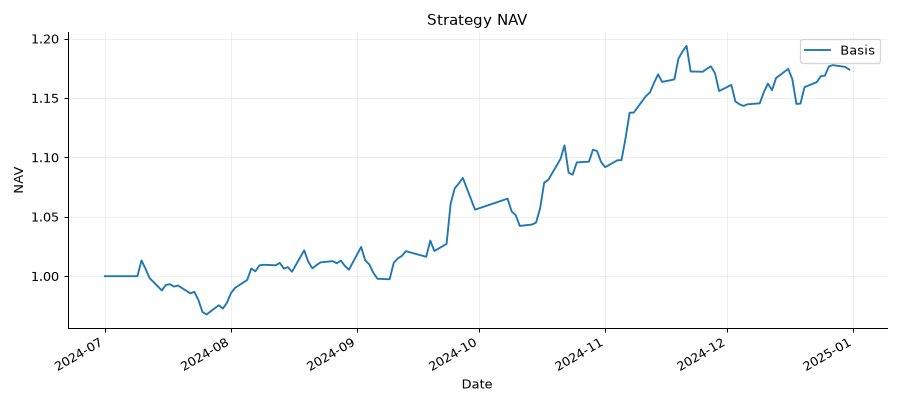

        区间收益   最大回撤
Basis 17.40% -4.49%


In [5]:
weights = make_weights('basis_signal')
nav, turnover = backtest(weights)  # 本章先看扣费前表现
result = show_result({'Basis': nav})


## 看结果

曲线从 1 开始，先看期末净值，再看中途跌过多少。这里是半年样例，历史预热、商品范围和执行口径与视频完整研究不同，结果不用于复现视频的年化数字。下一期再加交易成本。
